# EGF-TNFα signaling

This notebook reproduces the analysis of the EGF-TNFα signaling model of the [MaBoSS website](https://maboss.curie.fr).

This model was used as an example for the SBML-qual standard format
([Chaouiya et al., 2013](https://doi.org/10.1186/1752-0509-7-135)), and can be found in the
[BioModels](https://www.ebi.ac.uk/biomodels/BIOMD0000000562) database (BIOMD0000000562). The MaBoSS files
were exported from [GINsim](http://ginsim.org), with `egf` and `tnfa` as inputs.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `chaouiya_maboss.bnd` and
`chaouiya_maboss.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## Simulation

In the configuration file, the initial state of every node is random, and `ras`, `egf` and `akt` are the
output nodes. To reproduce the figure of the publication, we set the following conditions:

* all the nodes are initially inactive, except EGF, which is present in half of the cells (no TNFα);
* `erk` is also an output node, to follow its activity;
* the simulation runs until time 50.

In [2]:
sim = maboss.load("chaouiya_maboss.bnd", "chaouiya_maboss.cfg")
for node in sim.network:
    sim.network.set_istate(node, [1, 0])
sim.network.set_istate("egf", [0.5, 0.5])
sim.network["erk"].is_internal = False
sim.update_parameters(max_time=50, time_tick=0.1)
result = sim.run()

## Fixed points

The simulation reaches two fixed points:

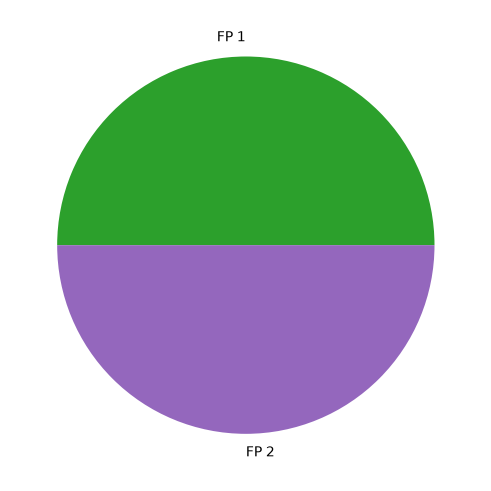

In [3]:
result.plot_fixpoint()
plt.savefig("figures/egf_tnf_fixed_points.png")

The table of the fixed points gives their probabilities, and the state of each node (1: active):

In [4]:
result.get_fptable()

,FP,Proba,State,mek,erk,nik,ikk,akt,gsk3,ikb,nfkb,traf2,ask1,sos,ras,egf,egfr,tnfr,ex,map3k1,tnfa,cjun,ap1,raf1,map3k7,mkk4,mkk7,jnk,ph,pi3k,p38
0,#1,0.50002,akt -- ikb -- egf -- egfr -- ph -- pi3k,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0
1,#2,0.49998,gsk3 -- ikb,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


They correspond to the stable states of the published model for the wild type: with EGF, AKT is active,
while without EGF, GSK3 is active.

## Trajectories

As in the publication, RAS is activated first, then ERK: their activities are transient, while AKT remains active
when EGF is present.

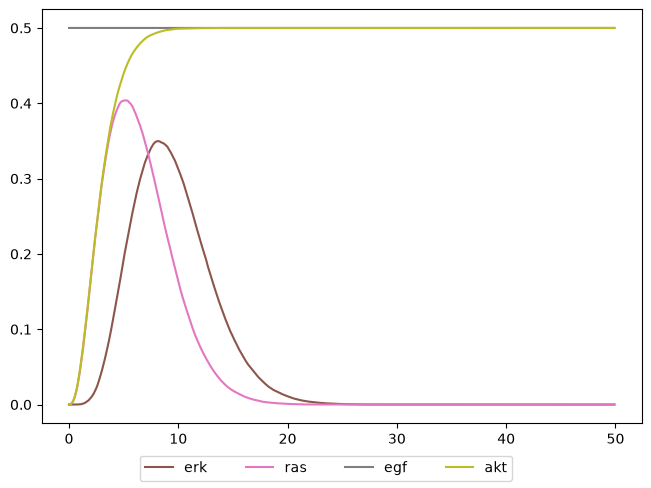

In [5]:
result.plot_node_trajectory()
legend_below()
plt.savefig("figures/egf_tnf_trajectories.png")